In [ ]:
!pip -q install timm gdown scikit-learn

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

ROOT = "/content/drive/MyDrive/dataset/MILK10k_Split"

TRAIN_DIR = os.path.join(ROOT, "train")
VAL_DIR = os.path.join(ROOT, "val")
TEST_DIR = os.path.join(ROOT, "test")

print("Dataset root:", ROOT)
print("Train:", TRAIN_DIR)
print("Val  :", VAL_DIR)
print("Test :", TEST_DIR)

print()
print("Train exists:", os.path.exists(TRAIN_DIR))
print("Val exists  :", os.path.exists(VAL_DIR))
print("Test exists :", os.path.exists(TEST_DIR))

assert os.path.exists(TRAIN_DIR), "Train folder not found"
assert os.path.exists(VAL_DIR), "Val folder not found"
assert os.path.exists(TEST_DIR), "Test folder not found"

print()
print("Dataset folders found successfully.")

Dataset root: /content/drive/MyDrive/dataset/MILK10k_Split
Train: /content/drive/MyDrive/dataset/MILK10k_Split/train
Val  : /content/drive/MyDrive/dataset/MILK10k_Split/val
Test : /content/drive/MyDrive/dataset/MILK10k_Split/test

Train exists: True
Val exists  : True
Test exists : True

Dataset folders found successfully.


In [ ]:
import os
import pandas as pd

TRAIN_DIR = os.path.join(ROOT, "train")
VAL_DIR = os.path.join(ROOT, "val")
TEST_DIR = os.path.join(ROOT, "test")

TRAIN_GT = os.path.join(TRAIN_DIR, "GroundTruth.csv")
VAL_GT = os.path.join(VAL_DIR, "GroundTruth.csv")
TEST_GT = os.path.join(TEST_DIR, "GroundTruth.csv")

train_df = pd.read_csv(TRAIN_GT)
val_df = pd.read_csv(VAL_GT)
test_df = pd.read_csv(TEST_GT)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nGroundTruth columns:")
print(train_df.columns.tolist())

display(train_df.head())

TRAIN_IMG_DIR = os.path.join(TRAIN_DIR, "images")
VAL_IMG_DIR = os.path.join(VAL_DIR, "images")
TEST_IMG_DIR = os.path.join(TEST_DIR, "images")

print("\nImage counts:")
print("Train images:", len(os.listdir(TRAIN_IMG_DIR)))
print("Val images:", len(os.listdir(VAL_IMG_DIR)))
print("Test images:", len(os.listdir(TEST_IMG_DIR)))

Train shape: (4192, 12)
Validation shape: (524, 12)
Test shape: (524, 12)

GroundTruth columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0006407,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,IL_0008891,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



Image counts:
Train images: 8384
Val images: 1048
Test images: 1048


In [ ]:
import os
import pandas as pd
from torch.utils.data import Dataset
from PIL import Image

TRAIN_DIR = os.path.join(ROOT, "train")
VAL_DIR = os.path.join(ROOT, "val")
TEST_DIR = os.path.join(ROOT, "test")

TRAIN_IMG_DIR = os.path.join(TRAIN_DIR, "images")
VAL_IMG_DIR = os.path.join(VAL_DIR, "images")
TEST_IMG_DIR = os.path.join(TEST_DIR, "images")

train_gt = pd.read_csv(
    os.path.join(TRAIN_DIR, "GroundTruth.csv")
)

val_gt = pd.read_csv(
    os.path.join(VAL_DIR, "GroundTruth.csv")
)

test_gt = pd.read_csv(
    os.path.join(TEST_DIR, "GroundTruth.csv")
)

train_meta = pd.read_csv(
    os.path.join(TRAIN_DIR, "Metadata.csv")
)

val_meta = pd.read_csv(
    os.path.join(VAL_DIR, "Metadata.csv")
)

test_meta = pd.read_csv(
    os.path.join(TEST_DIR, "Metadata.csv")
)

CLASS_NAMES = [
    "BCC",
    "SCCKA",
    "MEL",
    "NV",
    "BKL"
]

NUM_CLASSES = len(CLASS_NAMES)

print("================================")
print("SELECTED CLASSES")
print("================================")

for i, name in enumerate(CLASS_NAMES):
    print(i, "->", name)

print("Number of classes:", NUM_CLASSES)

def filter_classes(df):

    df = df.copy()

    df = df[
        df[CLASS_NAMES].sum(axis=1) > 0
    ].copy()

    df["label"] = df[CLASS_NAMES].values.argmax(axis=1)

    return df

train_gt = filter_classes(train_gt)
val_gt = filter_classes(val_gt)
test_gt = filter_classes(test_gt)

print("\n================================")
print("CLASS DISTRIBUTION")
print("================================")

for i, class_name in enumerate(CLASS_NAMES):

    train_count = (train_gt["label"] == i).sum()
    val_count = (val_gt["label"] == i).sum()
    test_count = (test_gt["label"] == i).sum()

    print(
        f"{class_name:6s} -> "
        f"Train: {train_count:4d} | "
        f"Val: {val_count:3d} | "
        f"Test: {test_count:3d}"
    )

def create_samples(
    gt_df,
    meta_df,
    image_dir
):

    meta_small = meta_df[
        ["lesion_id", "isic_id"]
    ].copy()

    gt_df = gt_df.copy()

    gt_df["lesion_id"] = (
        gt_df["lesion_id"].astype(str)
    )

    meta_small["lesion_id"] = (
        meta_small["lesion_id"].astype(str)
    )

    meta_small["isic_id"] = (
        meta_small["isic_id"].astype(str)
    )

    merged = pd.merge(
        gt_df[["lesion_id", "label"]],
        meta_small,
        on="lesion_id",
        how="inner"
    )

    samples = []

    for _, row in merged.iterrows():

        image_name = row["isic_id"] + ".jpg"

        image_path = os.path.join(
            image_dir,
            image_name
        )

        if os.path.exists(image_path):

            samples.append(
                (
                    image_path,
                    int(row["label"])
                )
            )

    return samples

print("\nCreating datasets...")

train_samples = create_samples(
    train_gt,
    train_meta,
    TRAIN_IMG_DIR
)

val_samples = create_samples(
    val_gt,
    val_meta,
    VAL_IMG_DIR
)

test_samples = create_samples(
    test_gt,
    test_meta,
    TEST_IMG_DIR
)

class SkinLesionDataset(Dataset):

    def __init__(
        self,
        samples,
        transform=None
    ):

        self.samples = samples
        self.transform = transform

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

train_dataset = SkinLesionDataset(
    train_samples
)

val_dataset = SkinLesionDataset(
    val_samples
)

test_dataset = SkinLesionDataset(
    test_samples
)

print("\n================================")
print("5-CLASS DATASET SUMMARY")
print("================================")

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

SELECTED CLASSES
0 -> BCC
1 -> SCCKA
2 -> MEL
3 -> NV
4 -> BKL
Number of classes: 5

CLASS DISTRIBUTION
BCC    -> Train: 2026 | Val: 255 | Test: 241
SCCKA  -> Train:  392 | Val:  40 | Test:  41
MEL    -> Train:  365 | Val:  43 | Test:  42
NV     -> Train:  577 | Val:  81 | Test:  88
BKL    -> Train:  431 | Val:  58 | Test:  55

Creating datasets...

5-CLASS DATASET SUMMARY
Train: 7582
Val  : 954
Test : 934


In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = SkinLesionDataset(
    train_samples,
    transform=train_transform
)

val_dataset = SkinLesionDataset(
    val_samples,
    transform=val_transform
)

test_dataset = SkinLesionDataset(
    test_samples,
    transform=test_transform
)

BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 474
Val batches: 60
Test batches: 59


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("Device:", DEVICE)

MODEL_CLASS_ORDER = [
    "bcc",
    "keratoses",
    "melanoma",
    "nevus",
    "scc"
]

NUM_CLASSES = 5


class ECAAttention(nn.Module):

    def __init__(self, channels, k_size=3):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.conv = nn.Conv1d(
            1,
            1,
            kernel_size=k_size,
            padding=(k_size - 1) // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        y = self.avg_pool(x)

        y = y.squeeze(-1).transpose(-1, -2)

        y = self.conv(y)

        y = self.sigmoid(y)

        y = y.transpose(-1, -2).unsqueeze(-1)

        return x * y


class EnhancedResNet50(nn.Module):

    def __init__(
        self,
        num_classes=5,
        dropout=0.4
    ):

        super().__init__()

        backbone = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2
        )

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.eca2 = ECAAttention(512)
        self.eca3 = ECAAttention(1024)
        self.eca4 = ECAAttention(2048)

        self.proj2 = nn.Sequential(
            nn.Conv2d(
                512,
                64,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.proj3 = nn.Sequential(
            nn.Conv2d(
                1024,
                96,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True)
        )

        self.proj4 = nn.Sequential(
            nn.Conv2d(
                2048,
                96,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True)
        )

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            64 + 96 + 96,
            num_classes
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)

        f2 = self.layer2(x)

        f3 = self.layer3(f2)

        f4 = self.layer4(f3)

        f2 = self.eca2(f2)
        f3 = self.eca3(f3)
        f4 = self.eca4(f4)

        f2 = self.proj2(f2)
        f3 = self.proj3(f3)
        f4 = self.proj4(f4)

        f2 = self.global_pool(f2)
        f3 = self.global_pool(f3)
        f4 = self.global_pool(f4)

        f2 = torch.flatten(f2, 1)
        f3 = torch.flatten(f3, 1)
        f4 = torch.flatten(f4, 1)

        fused = torch.cat(
            [f2, f3, f4],
            dim=1
        )

        fused = self.dropout(fused)

        output = self.fc(fused)

        return output


model = EnhancedResNet50(
    num_classes=NUM_CLASSES,
    dropout=0.4
).to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("ENHANCED RESNET-50")
print("=" * 60)

print("ResNet-50 + ECA + 3-Level Multi-Scale Fusion")

print("Layer2 channels : 64")
print("Layer3 channels : 96")
print("Layer4 channels : 96")

print("Fused features  :", 256)

print("Class order:")
print(MODEL_CLASS_ORDER)

print(
    "Total parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

dummy = torch.randn(
    2,
    3,
    224,
    224
).to(DEVICE)

with torch.no_grad():

    output = model(dummy)

print("Input :", dummy.shape)
print("Output:", output.shape)

del dummy

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 169MB/s]


ENHANCED RESNET-50
ResNet-50 + ECA + 3-Level Multi-Scale Fusion
Layer2 channels : 64
Layer3 channels : 96
Layer4 channels : 96
Fused features  : 256
Class order:
['bcc', 'keratoses', 'melanoma', 'nevus', 'scc']
Total parameters: 23,837,518
Trainable parameters: 23,837,518
Input : torch.Size([2, 3, 224, 224])
Output: torch.Size([2, 5])


In [ ]:
import numpy as np
import torch.optim as optim

class_counts = np.bincount(
    train_gt["label"].values,
    minlength=NUM_CLASSES
)

print("================================")
print("CLASS DISTRIBUTION")
print("================================")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:10s} : "
        f"{class_counts[i]}"
    )

total_samples = class_counts.sum()

class_weights = total_samples / (
    NUM_CLASSES * class_counts
)

print("\n================================")
print("CLASS WEIGHTS")
print("================================")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:10s} : "
        f"{class_weights[i]:.4f}"
    )

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.05
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("\n================================")
print("TRAINING SETTINGS")
print("================================")

print("Loss        : Weighted CrossEntropyLoss")
print("Optimizer   : AdamW")
print("Learning rate:", 0.0001)
print("Weight decay :", 0.05)
print("Scheduler    : ReduceLROnPlateau")

CLASS DISTRIBUTION
BCC        : 2026
SCCKA      : 392
MEL        : 365
NV         : 577
BKL        : 431

CLASS WEIGHTS
BCC        : 0.3742
SCCKA      : 1.9342
MEL        : 2.0773
NV         : 1.3140
BKL        : 1.7592

TRAINING SETTINGS
Loss        : Weighted CrossEntropyLoss
Optimizer   : AdamW
Learning rate: 0.0001
Weight decay : 0.05
Scheduler    : ReduceLROnPlateau


In [ ]:
import os
import time
import torch
import torch.nn as nn
from tqdm.auto import tqdm

EPOCHS = 50
LR = 1e-4
WEIGHT_DECAY = 0.05

CHECKPOINT_DIR = "/content/drive/MyDrive/skin_model_checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "enhanced_resnet50_lite_last.pth"
)

BEST_PATH = os.path.join(
    CHECKPOINT_DIR,
    "enhanced_resnet50_lite_best.pth"
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

scaler = torch.amp.GradScaler("cuda")

start_epoch = 1
best_val_acc = 0.0

if os.path.exists(CHECKPOINT_PATH):

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1

    best_val_acc = checkpoint.get(
        "best_val_acc",
        0.0
    )

    print(
        "Resuming from Epoch:",
        start_epoch
    )

else:

    print(
        "No enhanced ResNet checkpoint found."
    )

    print(
        "Starting training from Epoch 1."
    )


for epoch in range(
    start_epoch,
    EPOCHS + 1
):

    epoch_start = time.time()

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda"
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        train_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total

    train_acc = (
        train_correct /
        train_total
    )

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda"
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            val_loss += (
                loss.item() *
                images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total

    val_acc = (
        val_correct /
        val_total
    )

    scheduler.step(val_acc)

    epoch_time = (
        time.time() -
        epoch_start
    )

    print()
    print("=" * 70)
    print(f"Epoch {epoch}/{EPOCHS}")
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Acc  : {train_acc:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Acc    : {val_acc:.4f}")
    print(
        f"LR         : {optimizer.param_groups[0]['lr']:.7f}"
    )
    print(
        f"Epoch Time : {epoch_time / 60:.2f} minutes"
    )
    print("=" * 70)

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc
    }

    torch.save(
        checkpoint,
        CHECKPOINT_PATH
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        checkpoint["best_val_acc"] = best_val_acc

        torch.save(
            checkpoint,
            BEST_PATH
        )

        print("Best checkpoint saved.")

    print()

Resuming from Epoch: 43


Epoch 43/50:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch 43/50
Train Loss : 0.0061
Train Acc  : 0.9992
Val Loss   : 1.1515
Val Acc    : 0.7432
LR         : 0.0000010
Epoch Time : 1.33 minutes



Epoch 44/50:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch 44/50
Train Loss : 0.0063
Train Acc  : 0.9996
Val Loss   : 1.1416
Val Acc    : 0.7453
LR         : 0.0000010
Epoch Time : 1.35 minutes



...


Epoch 48/50
Train Loss : 0.0058
Train Acc  : 0.9996
Val Loss   : 1.2102
Val Acc    : 0.7306
LR         : 0.0000010
Epoch Time : 1.36 minutes



Epoch 49/50:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch 49/50
Train Loss : 0.0051
Train Acc  : 0.9999
Val Loss   : 1.1216
Val Acc    : 0.7358
LR         : 0.0000010
Epoch Time : 1.34 minutes



Epoch 50/50:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch 50/50
Train Loss : 0.0059
Train Acc  : 0.9996
Val Loss   : 1.2113
Val Acc    : 0.7317
LR         : 0.0000010
Epoch Time : 1.37 minutes



In [ ]:
import os
import torch

CHECKPOINT_PATH = "/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_last.pth"

print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    print("Last completed epoch:", checkpoint["epoch"])
    print("Best Validation Accuracy:", checkpoint.get("best_val_acc", "Not found"))
else:
    print("Checkpoint not found at this location.")

Checkpoint exists: True
Last completed epoch: 50
Best Validation Accuracy: 0.7693920335429769


In [ ]:
import os
import torch

print("Searching for Enhanced ResNet checkpoint...")

CHECKPOINT_DIR = "/content/drive/MyDrive"

checkpoint_candidates = []

for root, dirs, files in os.walk(CHECKPOINT_DIR):
    for file in files:
        if file.endswith(".pth") and "enhanced_resnet50" in file.lower():
            checkpoint_candidates.append(
                os.path.join(root, file)
            )

print("")

if len(checkpoint_candidates) == 0:
    print("No Enhanced ResNet checkpoint found in Google Drive.")
    print("")
    print("Expected checkpoint files:")
    print("enhanced_resnet50_best.pth")
    print("enhanced_resnet50_last.pth")
    print("enhanced_resnet50_lite_best.pth")
    print("enhanced_resnet50_lite_last.pth")

else:
    print("Checkpoint(s) found:")
    for path in checkpoint_candidates:
        print(path)

    BEST_CHECKPOINT = None

    for path in checkpoint_candidates:
        if "best" in os.path.basename(path).lower():
            BEST_CHECKPOINT = path
            break

    if BEST_CHECKPOINT is None:
        BEST_CHECKPOINT = checkpoint_candidates[0]

    print("")
    print("Loading checkpoint:")
    print(BEST_CHECKPOINT)

    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(DEVICE)
    model.eval()

    print("")
    print("================================")
    print("BEST ENHANCED RESNET MODEL")
    print("================================")

    print(
        "Checkpoint:",
        BEST_CHECKPOINT
    )

    print(
        "Best Epoch:",
        checkpoint["epoch"]
    )

    if "best_val_f1" in checkpoint:
        print(
            "Best Validation Macro-F1:",
            f"{checkpoint['best_val_f1']:.4f}"
        )
    elif "best_val_acc" in checkpoint:
        print(
            "Best Validation Accuracy:",
            f"{checkpoint['best_val_acc']:.4f}"
        )
    else:
        print(
            "Best validation metric: Not stored in checkpoint"
        )

    print("Model loaded successfully.")

Searching for Enhanced ResNet checkpoint...

Checkpoint(s) found:
/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_best.pth
/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_last.pth

Loading checkpoint:
/content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_best.pth

BEST ENHANCED RESNET MODEL
Checkpoint: /content/drive/MyDrive/skin_model_checkpoints/enhanced_resnet50_lite_best.pth
Best Epoch: 9
Best Validation Accuracy: 0.7694
Model loaded successfully.


In [ ]:
import numpy as np
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

CLASS_NAMES_DISPLAY = [
    "BCC",
    "SCC",
    "Melanoma",
    "Nevus",
    "Keratoses"
]

model.eval()

test_true = []
test_pred = []

test_loss = 0.0

with torch.no_grad():

    test_bar = tqdm(
        test_loader,
        desc="Testing",
        unit="batch"
    )

    for images, labels in test_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        test_loss += (
            loss.item()
            *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_true.extend(
            labels.cpu().numpy()
        )

        test_pred.extend(
            predictions.cpu().numpy()
        )

test_loss = (
    test_loss
    /
    len(test_dataset)
)

test_accuracy = accuracy_score(
    test_true,
    test_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    test_true,
    test_pred
)

test_macro_precision = precision_score(
    test_true,
    test_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    test_true,
    test_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    test_true,
    test_pred,
    average="macro",
    zero_division=0
)

test_weighted_precision = precision_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_weighted_recall = recall_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_weighted_f1 = f1_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

print("\n")
print("=" * 65)
print("FINAL TEST RESULTS - ENHANCED RESNET-50")
print("=" * 65)

print(
    f"Test Loss              : {test_loss:.4f}"
)

print(
    f"Test Accuracy          : {test_accuracy:.4f}"
)

print(
    f"Test Balanced Accuracy : "
    f"{test_balanced_accuracy:.4f}"
)

print(
    f"Test Macro Precision   : "
    f"{test_macro_precision:.4f}"
)

print(
    f"Test Macro Recall      : "
    f"{test_macro_recall:.4f}"
)

print(
    f"Test Macro F1          : "
    f"{test_macro_f1:.4f}"
)

print(
    f"Test Weighted Precision: "
    f"{test_weighted_precision:.4f}"
)

print(
    f"Test Weighted Recall   : "
    f"{test_weighted_recall:.4f}"
)

print(
    f"Test Weighted F1       : "
    f"{test_weighted_f1:.4f}"
)

print("\n")
print("=" * 65)
print("PER-CLASS TEST METRICS")
print("=" * 65)

print(
    classification_report(
        test_true,
        test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES_DISPLAY,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    test_true,
    test_pred,
    labels=np.arange(NUM_CLASSES)
)

print("\n")
print("=" * 65)
print("CONFUSION MATRIX")
print("=" * 65)

print("Rows    = Actual")
print("Columns = Predicted\n")

print(
    CLASS_NAMES_DISPLAY
)

print(cm)

Testing:   0%|          | 0/59 [00:00<?, ?batch/s]



FINAL TEST RESULTS - ENHANCED RESNET-50
Test Loss              : 0.8735
Test Accuracy          : 0.7302
Test Balanced Accuracy : 0.5697
Test Macro Precision   : 0.6220
Test Macro Recall      : 0.5697
Test Macro F1          : 0.5896
Test Weighted Precision: 0.7068
Test Weighted Recall   : 0.7302
Test Weighted F1       : 0.7136


PER-CLASS TEST METRICS
              precision    recall  f1-score   support

         BCC     0.8116    0.9295    0.8665       482
         SCC     0.6129    0.4634    0.5278        82
    Melanoma     0.5507    0.4524    0.4967        84
       Nevus     0.7216    0.7216    0.7216       176
   Keratoses     0.4133    0.2818    0.3351       110

    accuracy                         0.7302       934
   macro avg     0.6220    0.5697    0.5896       934
weighted avg     0.7068    0.7302    0.7136       934



CONFUSION MATRIX
Rows    = Actual
Columns = Predicted

['BCC', 'SCC', 'Melanoma', 'Nevus', 'Keratoses']
[[448  12   4   4  14]
 [ 31  38   1   0  12]
 [  

<Figure size 800x700 with 0 Axes>

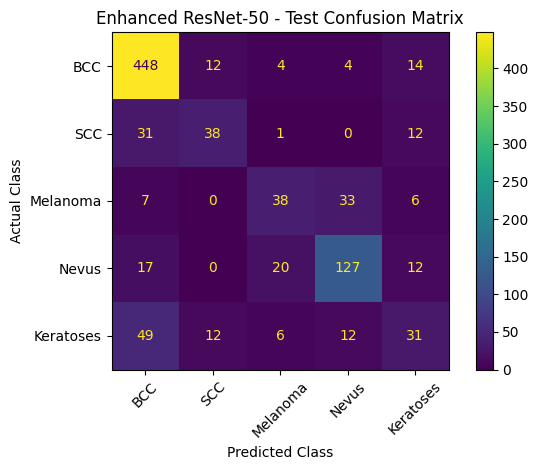

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(
    figsize=(8, 7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES_DISPLAY
)

disp.plot(
    values_format="d",
    xticks_rotation=45
)

plt.title(
    "Enhanced ResNet-50 - Test Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()

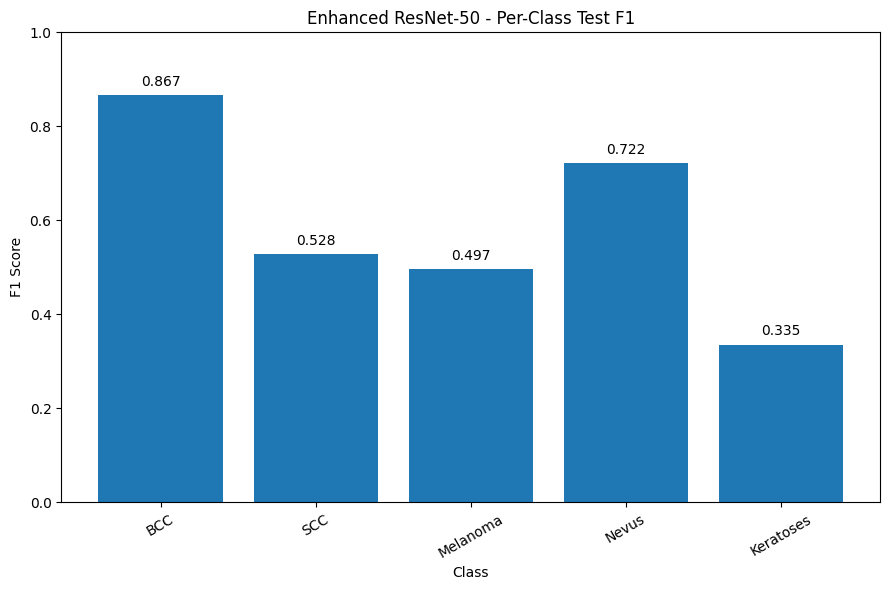

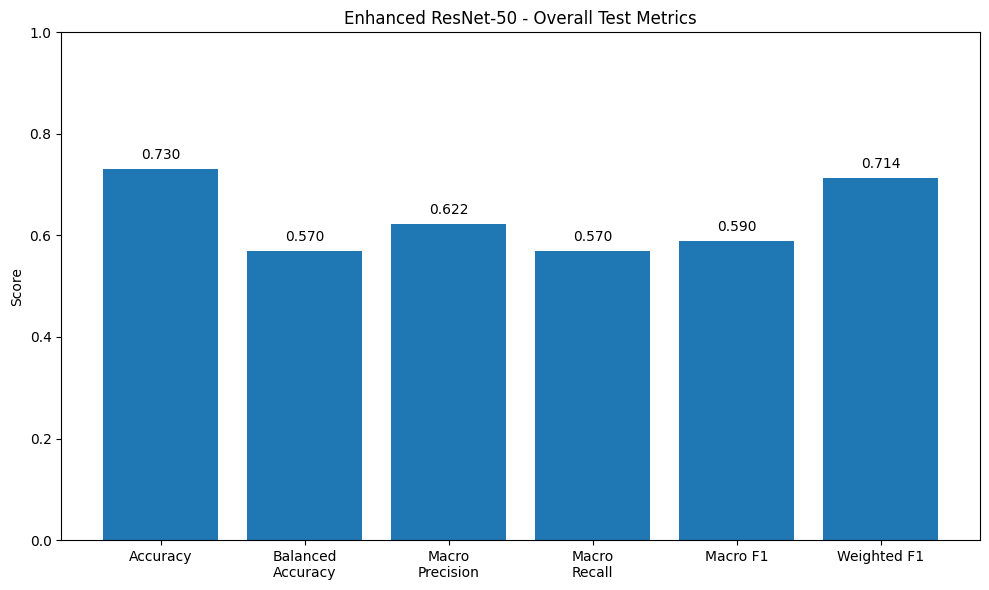

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

per_class_f1 = f1_score(
    test_true,
    test_pred,
    average=None,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    CLASS_NAMES_DISPLAY,
    per_class_f1
)

plt.ylim(
    0,
    1
)

plt.xlabel(
    "Class"
)

plt.ylabel(
    "F1 Score"
)

plt.title(
    "Enhanced ResNet-50 - Per-Class Test F1"
)

plt.xticks(
    rotation=30
)

for i, value in enumerate(
    per_class_f1
):

    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.show()


metric_names = [
    "Accuracy",
    "Balanced\nAccuracy",
    "Macro\nPrecision",
    "Macro\nRecall",
    "Macro F1",
    "Weighted F1"
]

metric_values = [
    test_accuracy,
    test_balanced_accuracy,
    test_macro_precision,
    test_macro_recall,
    test_macro_f1,
    test_weighted_f1
]

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    metric_names,
    metric_values
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Score"
)

plt.title(
    "Enhanced ResNet-50 - Overall Test Metrics"
)

for i, value in enumerate(
    metric_values
):

    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.show()

<Figure size 800x700 with 0 Axes>

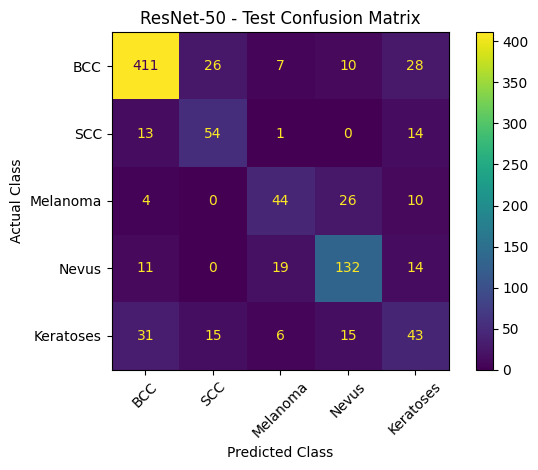

In [ ]:
# ============================================================
# CELL 11 - CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------------------------
# CONFUSION MATRIX DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES_DISPLAY
)

disp.plot(
    values_format="d",
    xticks_rotation=45
)

plt.title("ResNet-50 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

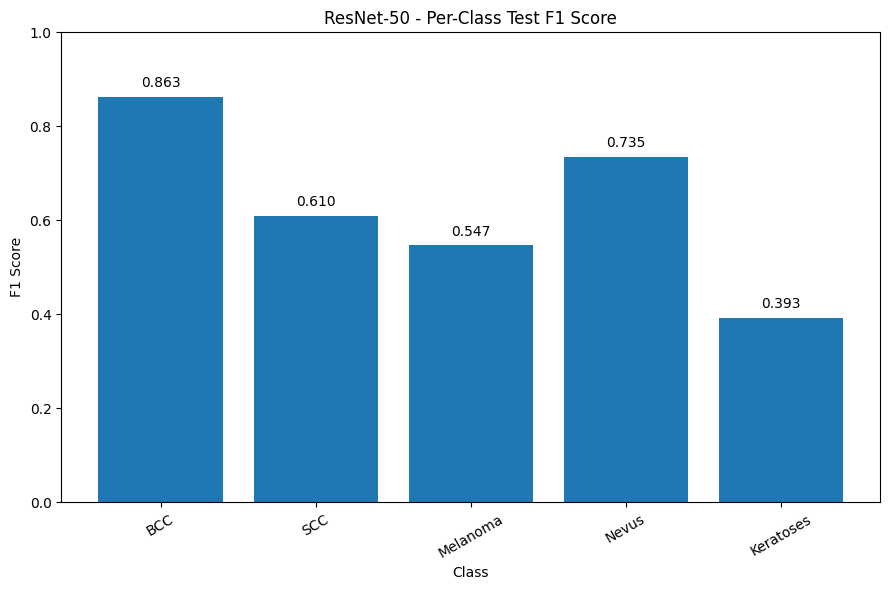

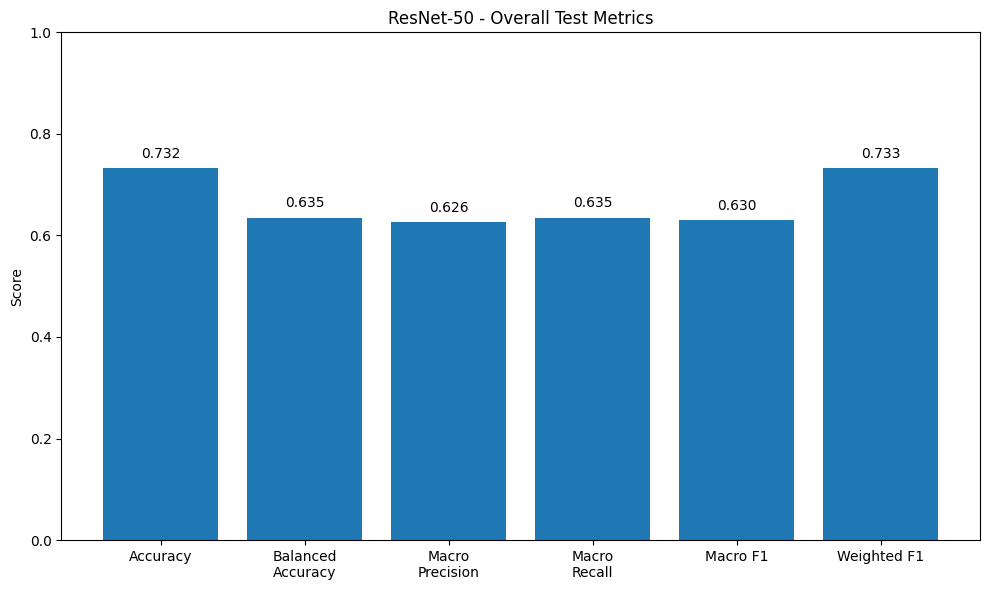

In [ ]:
# ============================================================
# CELL 12 - TEST METRICS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# PER-CLASS F1
# ------------------------------------------------------------

per_class_f1 = f1_score(
    test_true,
    test_pred,
    average=None,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)

plt.figure(figsize=(9, 6))

plt.bar(
    CLASS_NAMES_DISPLAY,
    per_class_f1
)

plt.ylim(0, 1)

plt.xlabel("Class")
plt.ylabel("F1 Score")
plt.title("ResNet-50 - Per-Class Test F1 Score")

plt.xticks(rotation=30)

# Add values on bars
for i, value in enumerate(per_class_f1):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# OVERALL METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Balanced\nAccuracy",
    "Macro\nPrecision",
    "Macro\nRecall",
    "Macro F1",
    "Weighted F1"
]

metric_values = [
    test_accuracy,
    test_balanced_accuracy,
    test_macro_precision,
    test_macro_recall,
    test_macro_f1,
    test_weighted_f1
]

plt.figure(figsize=(10, 6))

plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.title("ResNet-50 - Overall Test Metrics")

for i, value in enumerate(metric_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()